Source:  
https://www.youtube.com/watch?v=TyvYZ26alZs.  

Google Collab:  
https://colab.research.google.com/drive/1tRzL1GGOJDgz7CHSY1HECd4IwNAjuip5?usp=sharing

## Fitted to Fashion Mnist data

In [1]:
import pandas as pd
import numpy as np
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import xgboost as xgb
from xgboost import XGBClassifier, plot_tree
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
from sklearn.tree import export_graphviz

In [2]:
# LLM-assisted (Claude, 2026-11-24): load Fashion-MNIST from .npz and flatten to 784 features in [0, 1].
data = np.load("fashion_mnist.npz")
x_train_full = data["x_train"].reshape(-1, 784) / 255.0   # (60000, 784)
y_train_full = data["y_train"]                            # (60000,)
x_test = data["x_test"].reshape(-1, 784) / 255.0          # (10000, 784)
y_test = data["y_test"]

x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full, test_size=0.2, stratify=y_train_full, random_state=2026)


rng = np.random.default_rng(2026)
sub = np.concatenate([rng.choice(np.where(y_train == c)[0], 1000, replace=False) for c in range(10)])
X_sub, y_sub = x_train[sub], y_train[sub]


In [3]:
model = RandomForestClassifier(50, max_depth=6, max_features=15)
model.fit(x_train, y_train)
print(model.score(x_val, y_val))

0.7943333333333333


In [4]:
model2 = XGBClassifier(objective='multi:softmax', learning_rate = 0.1,
              max_depth = 6, n_estimators = 50, tree_method="hist")
model2.fit(x_train[:5000], y_train[:5000])
preds = model2.predict(x_test)
print(sum(preds==y_test)/len(y_test))

0.8412


In [5]:
# LLM-assisted (Claude, 2026-11-24): plot the mean image of each Fashion-MNIST class.
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

"""fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for k, ax in enumerate(axes.flat):
    mean_img = x_train[y_train == k].mean(axis=0).reshape(28, 28)  # average over all images of class k
    ax.imshow(mean_img, cmap="gray", vmin=0, vmax=1)
    ax.set_title(class_names[k])
    ax.axis("off")
plt.tight_layout()
plt.show()
# Imshow 
plt.imshow(model2.feature_importances_.reshape(28, 28), cmap="hot"); plt.colorbar();"""


'fig, axes = plt.subplots(2, 5, figsize=(12, 5))\nfor k, ax in enumerate(axes.flat):\n    mean_img = x_train[y_train == k].mean(axis=0).reshape(28, 28)  # average over all images of class k\n    ax.imshow(mean_img, cmap="gray", vmin=0, vmax=1)\n    ax.set_title(class_names[k])\n    ax.axis("off")\nplt.tight_layout()\nplt.show()\n# Imshow \nplt.imshow(model2.feature_importances_.reshape(28, 28), cmap="hot"); plt.colorbar();'

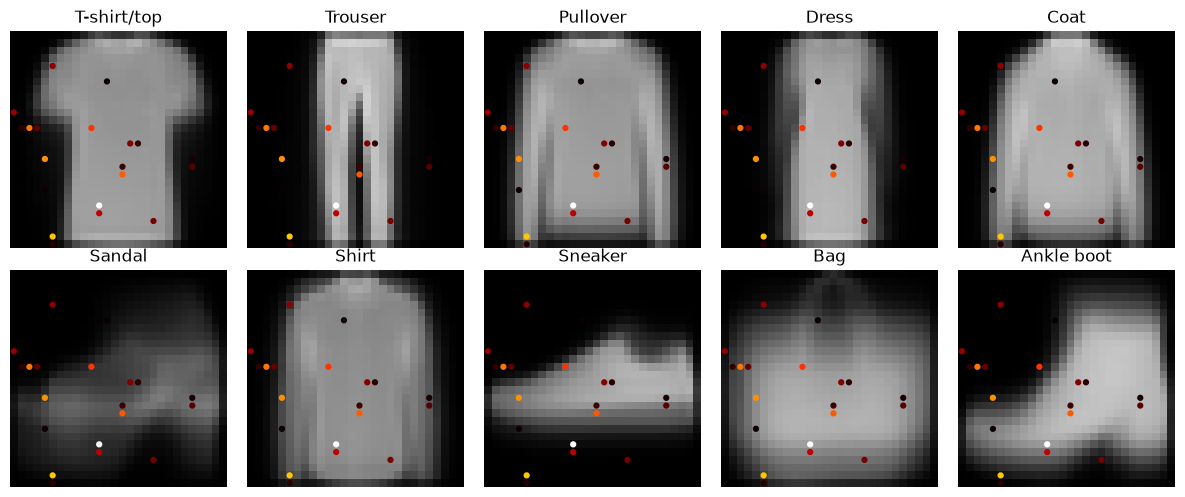

In [6]:
# LLM-assisted (Claude, 2026-11-24): mark the 20 most important XGBoost pixels on each class mean.
imp = model2.feature_importances_
top = np.argsort(imp)[-20:]              # indices of the 20 most important pixels
rows, cols = np.unravel_index(top, (28, 28))

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for k, ax in enumerate(axes.flat):
    ax.imshow(x_train[y_train == k].mean(axis=0).reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    ax.scatter(cols, rows, s=12, c=imp[top], cmap="hot")    # scatter takes (x, y) = (column, row)
    ax.set_title(class_names[k])
    ax.axis("off")
plt.tight_layout()
plt.show()


In [7]:

# LLM-assisted (Claude, 2026-11-24): XGBoost grid search with early stopping instead of tuning n_estimators.
from sklearn.model_selection import GridSearchCV, StratifiedKFold

xgb_model = XGBClassifier(
    objective="multi:softprob",
    n_estimators=500,            # upper limit, rarely reached
    early_stopping_rounds=20,    # stop if val loss hasn't improved in 20 rounds
    eval_metric="mlogloss",      # multiclass cross-entropy, monitored on eval_set
    tree_method="hist", random_state=2026, n_jobs=1)

param_grid = {
    "learning_rate": [0.03, 0.1, 0.3],
    "max_depth":     [1, 3, 6, 9],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)
search = GridSearchCV(xgb_model, param_grid, cv=cv, scoring="accuracy",
                      n_jobs=2, verbose=3, return_train_score=True)

# eval_set is passed on to XGBClassifier.fit in every fold
search.fit(X_sub, y_sub, eval_set=[(x_val, y_val)], verbose=False)

#print(search.best_params_, search.best_score_)
#print("Number of rounds used:", search.best_estimator_.best_iteration + 1)



Fitting 5 folds for each of 12 candidates, totalling 60 fits
[CV 2/5] END learning_rate=0.03, max_depth=1;, score=(train=0.842, test=0.812) total time= 2.8min
[CV 1/5] END learning_rate=0.03, max_depth=1;, score=(train=0.842, test=0.814) total time= 2.8min
[CV 3/5] END learning_rate=0.03, max_depth=1;, score=(train=0.843, test=0.816) total time= 2.8min
[CV 4/5] END learning_rate=0.03, max_depth=1;, score=(train=0.839, test=0.821) total time= 2.8min
[CV 5/5] END learning_rate=0.03, max_depth=1;, score=(train=0.840, test=0.812) total time= 2.8min
[CV 1/5] END learning_rate=0.03, max_depth=3;, score=(train=0.964, test=0.867) total time= 6.5min
[CV 2/5] END learning_rate=0.03, max_depth=3;, score=(train=0.964, test=0.859) total time= 6.6min
[CV 3/5] END learning_rate=0.03, max_depth=3;, score=(train=0.966, test=0.865) total time= 6.7min
[CV 4/5] END learning_rate=0.03, max_depth=3;, score=(train=0.961, test=0.871) total time= 5.5min
[CV 5/5] END learning_rate=0.03, max_depth=3;, score=(tra

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.03, 0.1, ...], 'max_depth': [1, 3, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",2
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",3
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``b

In [8]:
# LLM-assisted (Claude, 2026-11-25): make Project3/Code importable from Test-code.
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent / "Code"))   # Test-code -> Project3 -> Code

from Structure.Gridsearch import *

df = search_table(search)
#print(df)
best_idx = df["val"].idxmax()
best_val = df.loc[best_idx, "val"]
best_se = df.loc[best_idx, "val_se"]
se_lim = best_val - best_se
strong_eligible = df[df["val"] >= se_lim]
weak_eligible = df[(df["val"] + df["val_se"]) >= se_lim] # All values
print(strong_eligible)

   learning_rate  max_depth     val    val_se     train     fit_time
2           0.03          6  0.8703  0.002289  1.000000  1103.641117
5           0.10          3  0.8696  0.002310  0.996675   145.427314
6           0.10          6  0.8691  0.001699  1.000000   161.288677


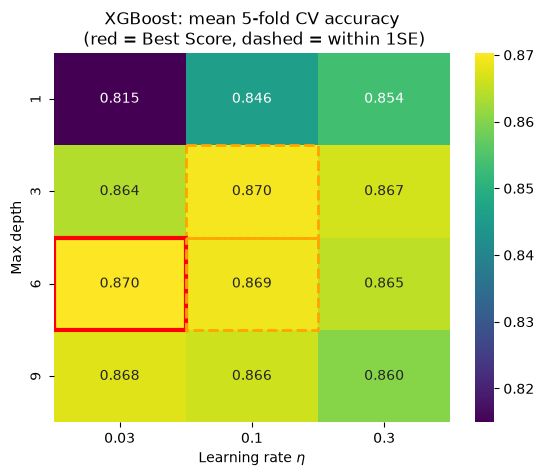

In [9]:
# LLM-assisted (Claude, 2026-11-24): heat map of mean CV accuracy for learning_rate x max_depth.
# With ONE-SE limits created with Claude code assistance (Skeleton) [2]
import seaborn as sns
from matplotlib.patches import Rectangle

table = df.pivot(index="max_depth", columns="learning_rate", values = "val")
se_table = df.pivot(index="max_depth", columns="learning_rate", values="val_se")

ax = sns.heatmap(table, annot=True, fmt=".3f", cmap="viridis")

for i in range(table.shape[0]):
    for j in range(table.shape[1]):
        val, se = table.iloc[i,j], se_table.iloc[i, j]
        if val >= se_lim:                     # strong: the mean itself is within 1 SE of the best
            ax.add_patch(Rectangle((j, i), 1, 1, fill=False, edgecolor="orange", lw=2, ls="--"))
        if val == best_val:
            ax.add_patch(Rectangle((j, i), 1, 1, fill=False, edgecolor="red", lw=3))
        
plt.xlabel(r"Learning rate $\eta$")
plt.ylabel("Max depth")
plt.title("XGBoost: mean 5-fold CV accuracy\n (red = Best Score, dashed = within 1SE)")
plt.show()


In [10]:
best_tree = search.best_estimator_
best_params = search.best_params_

final_model = XGBClassifier(
    objective="multi:softprob", n_estimators=2000, early_stopping_rounds=20,
    # LLM-assisted (Claude Code, 2026-11-25): track merror too for the loss plot; mlogloss last,
    # so early stopping still monitors the validation loss.
    eval_metric=["merror", "mlogloss"], tree_method="hist", random_state=2026, n_jobs=-1,
    **best_params
)
# Added [x_train,y_train] to eval_set for loss plot
final_model.fit(x_train, y_train, eval_set=[(x_train, y_train), (x_val, y_val)], verbose=False)

print("Rounds used:", final_model.best_iteration + 1)
print("Test accuracy:", accuracy_score(y_test, final_model.predict(x_test)))

Rounds used: 931
Test accuracy: 0.8991


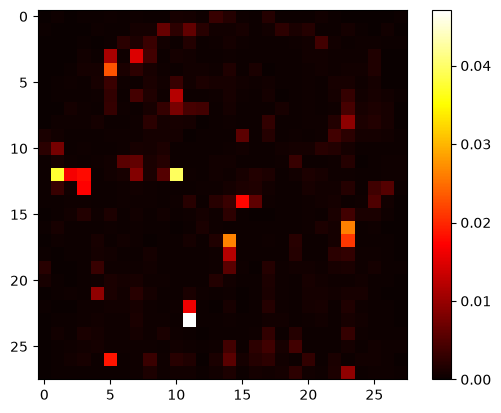

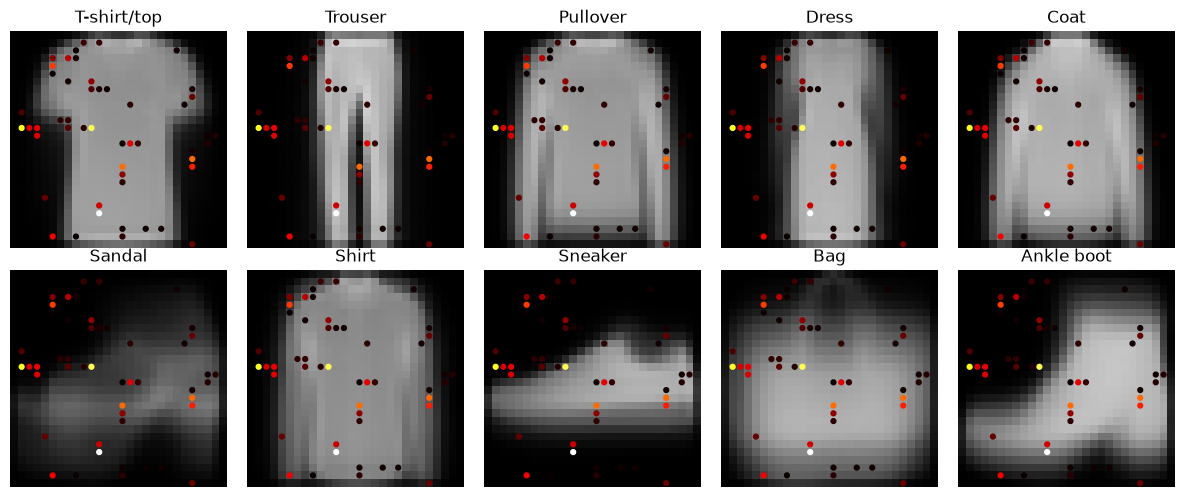

In [11]:
plt.imshow(final_model.feature_importances_.reshape(28, 28), cmap="hot"); plt.colorbar();

imp = final_model.feature_importances_
top = np.argsort(imp)[-50:]              # indices of the 50 most important pixels
rows, cols = np.unravel_index(top, (28, 28))

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for k, ax in enumerate(axes.flat):
    ax.imshow(x_train[y_train == k].mean(axis=0).reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    ax.scatter(cols, rows, s=12, c=imp[top], cmap="hot")    # scatter takes (x, y) = (column, row)
    ax.set_title(class_names[k])
    ax.axis("off")
plt.tight_layout()
plt.show()

[9 2 1 ... 8 1 5]
accuracy: 89.910000%


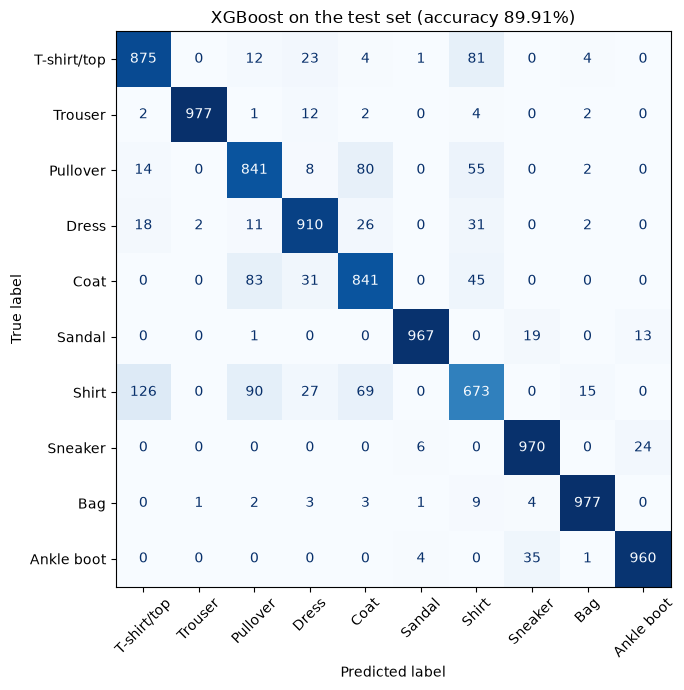

In [12]:
# LLM-assisted (Claude, 2026-11-25): Confusion matrix with scikit metrics
from sklearn.metrics import confusion_matrix as sk_confusion_matrix, ConfusionMatrixDisplay

full_prediction = final_model.predict(x_test)
accuracy = accuracy_score(y_test, full_prediction)
print(full_prediction)
print(f"accuracy: {accuracy:%}")

cm = sk_confusion_matrix(y_test, full_prediction)

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
ax.set_title(f"XGBoost on the test set (accuracy {accuracy:.2%})")
plt.tight_layout()
plt.show()

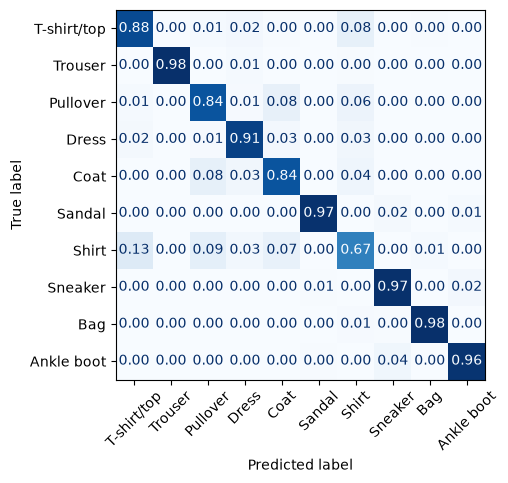

In [13]:
# LLM-assisted (Claude, 2026-11-25): CM: normalized values
cm_norm = sk_confusion_matrix(y_test, full_prediction, normalize="true")
ConfusionMatrixDisplay(cm_norm, display_labels=class_names).plot(
    cmap="Blues", colorbar=False, xticks_rotation=45, values_format=".2f")


In [14]:
from sklearn.metrics import classification_report
print(classification_report(y_test, full_prediction, target_names=class_names, digits=3))


              precision    recall  f1-score   support

 T-shirt/top      0.845     0.875     0.860      1000
     Trouser      0.997     0.977     0.987      1000
    Pullover      0.808     0.841     0.824      1000
       Dress      0.897     0.910     0.904      1000
        Coat      0.820     0.841     0.831      1000
      Sandal      0.988     0.967     0.977      1000
       Shirt      0.749     0.673     0.709      1000
     Sneaker      0.944     0.970     0.957      1000
         Bag      0.974     0.977     0.976      1000
  Ankle boot      0.963     0.960     0.961      1000

    accuracy                          0.899     10000
   macro avg      0.899     0.899     0.899     10000
weighted avg      0.899     0.899     0.899     10000



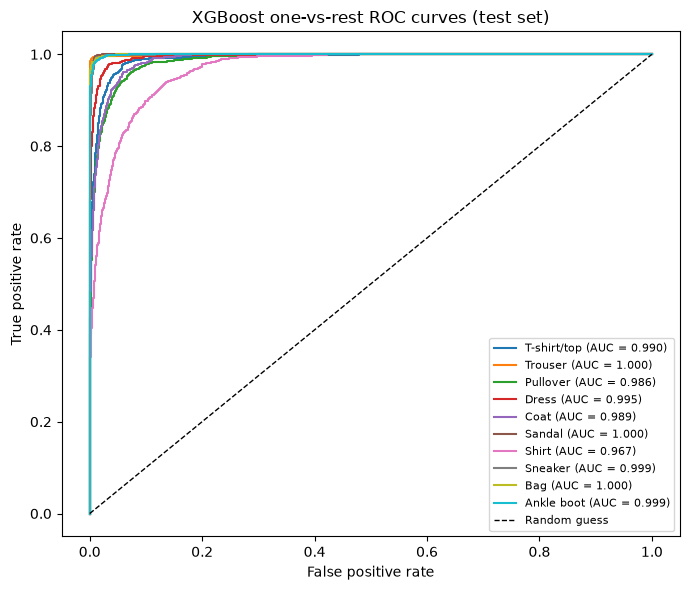

Macro-average AUC: 0.9925381555555557


In [15]:
# # LLM-assisted (Claude, 2026-11-25): ROC Curve
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.preprocessing import label_binarize

proba = final_model.predict_proba(x_test)          # (10000, 10)
y_bin = label_binarize(y_test, classes=range(10))   # one-hot, (10000, 10)

fig, ax = plt.subplots(figsize=(7, 6))
for k in range(10):
    fpr, tpr, _ = roc_curve(y_bin[:, k], proba[:, k])
    auc_k = roc_auc_score(y_bin[:, k], proba[:, k])
    ax.plot(fpr, tpr, lw=1.5, label=f"{class_names[k]} (AUC = {auc_k:.3f})")

ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random guess")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("XGBoost one-vs-rest ROC curves (test set)")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

print("Macro-average AUC:", roc_auc_score(y_test, proba, multi_class="ovr", average="macro"))


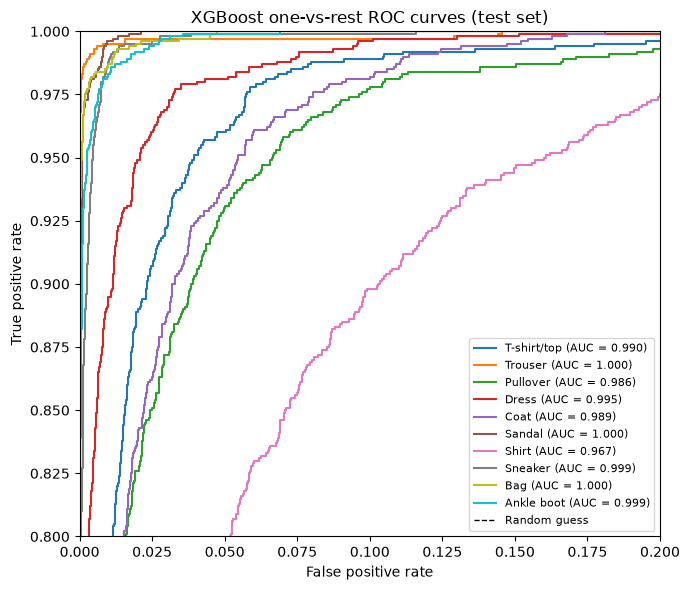

In [16]:
# # LLM-assisted (Claude, 2026-11-25): ROC Curve
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.preprocessing import label_binarize

proba = final_model.predict_proba(x_test)          # (10000, 10)
y_bin = label_binarize(y_test, classes=range(10))   # one-hot, (10000, 10)

fig, ax = plt.subplots(figsize=(7, 6))
for k in range(10):
    fpr, tpr, _ = roc_curve(y_bin[:, k], proba[:, k])
    auc_k = roc_auc_score(y_bin[:, k], proba[:, k])
    ax.plot(fpr, tpr, lw=1.5, label=f"{class_names[k]} (AUC = {auc_k:.3f})")

ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random guess")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("XGBoost one-vs-rest ROC curves (test set)")
ax.legend(fontsize=8, loc="lower right")
ax.set_xlim(0,0.2)
ax.set_ylim(0.8,1)
plt.tight_layout()
plt.show()


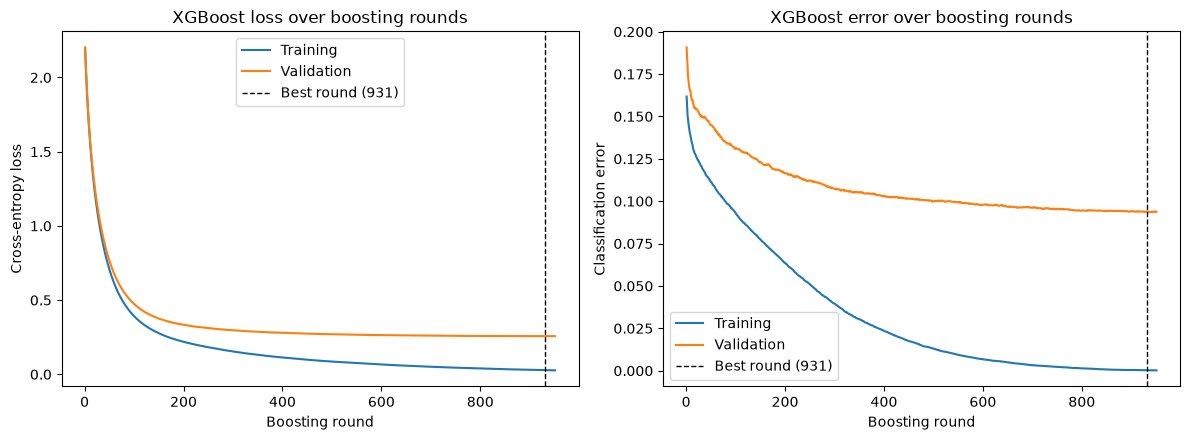

In [17]:
#  Loss over Boosting Rounds / discussion
# LLM Assisted [Claude - 25.11.26]
res = final_model.evals_result_
rounds = np.arange(1, len(res["validation_0"]["mlogloss"]) + 1)
best = final_model.best_iteration + 1

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, metric, label in zip(axes, ["mlogloss", "merror"],
                             ["Cross-entropy loss", "Classification error"]):
    ax.plot(rounds, res["validation_0"][metric], label="Training")
    ax.plot(rounds, res["validation_1"][metric], label="Validation")
    ax.axvline(best, color="k", ls="--", lw=1, label=f"Best round ({best})")
    ax.set_xlabel("Boosting round")
    ax.set_ylabel(label)
    ax.legend()
axes[0].set_title("XGBoost loss over boosting rounds")
axes[1].set_title("XGBoost error over boosting rounds")
plt.tight_layout()
plt.show()


In [18]:
# LLM-assisted (Claude Code, 2026-11-25): store test-set metrics in the shared comparison table
# (Project3/Results/model_comparison.csv) with Structure/Evaluation.py. Both models are evaluated
# on the full 10 000-image test set; rerunning overwrites the rows for these model names.
from Structure.Evaluation import evaluate, load_table   # Code/ is already on sys.path (cell 8)

evaluate("XGBoost", final_model, x_test, y_test, n_train=len(x_train))
evaluate("Random Forest (untuned baseline)", model, x_test, y_test, n_train=len(x_train))

print(load_table().to_string(index=False, float_format="%.4f"))


                           Model  Training size  Accuracy  Accuracy SE  Macro F1  Macro AUC  Log loss
                         XGBoost          48000    0.8991       0.0030    0.8985     0.9925    0.2863
Random Forest (untuned baseline)          48000    0.7871       0.0041    0.7789     0.9748    0.7051
